# Analisis Geoelectoral

Usaremos los mapas proporcionados por el INE para delimitar las secciones.

In [9]:
import os
import geopandas as gpd
from vothmo.config import FOLDER_RAW, FOLDER_DATA
from zipfile import ZipFile

# Extraccion de archivos descargados
FOLDER_MAP = FOLDER_RAW / "Mapas"
if not os.path.exists(FOLDER_MAP):
    print("Descargar Mapas")
else:
    DATA_MAPS = FOLDER_DATA / "Mapas"
    if not os.path.exists(FOLDER_DATA / "Mapas"):
        os.mkdir(DATA_MAPS)
    for folder in os.listdir(FOLDER_MAP):
        maps = os.listdir(FOLDER_MAP / folder)
        if not os.path.exists(DATA_MAPS / folder):
            os.mkdir(DATA_MAPS / folder)
        for file in maps:
            with ZipFile(FOLDER_MAP / folder / file, "r") as mzip:
                mzip.extractall(DATA_MAPS / folder)


Una vez con los archivos extraidos comenzamos la exploración.

In [24]:
folders = os.listdir(DATA_MAPS)
shpmaps = []
for folder in folders:
    files = os.listdir(DATA_MAPS / folder)
    for f in files:
        if f.endswith(".shp"):
            shpmaps.append(DATA_MAPS / folder / f)

shpmaps

[PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Mapas/2020/DISTRITO_FEDERAL.shp'),
 PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Mapas/2020/ENTIDAD.shp'),
 PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Mapas/2020/SECCION.shp'),
 PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Mapas/2020/MUNICIPIO.shp'),
 PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Mapas/2020/LOCALIDAD.shp'),
 PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Mapas/2020/DISTRITO_LOCAL.shp'),
 PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Mapas/2020/MANZANAS.shp'),
 PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Mapas/2021/SECCION.shp'),
 PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Mapas/2021/DISTRITO_FEDERAL.shp'),
 PosixPath('/home/david/Documents/Repositories/academica/Vota

In [58]:
k = 7
# 5, 6
print(shpmaps[k])
file = gpd.read_file(shpmaps[k])

/home/david/Documents/Repositories/academica/Votacion2026/data/Mapas/2021/SECCION.shp


In [60]:
sonfile = file[file['entidad']==26]
sonfile

,gid,id,entidad,distrito_f,distrito_l,municipio,seccion,tipo,geometry1_,ln,pad,geometry
51890,90475,134371,26,3,8,49,1465,2,None,298,298,"POLYGON ((-878053.278 1922236.069, -878197.798..."
53921,105323,133752,26,6,16,59,840,2,None,330,330,"POLYGON ((-782369.847 1735581.509, -782310.807..."
63732,72561,133584,26,1,1,55,671,2,None,382,382,"POLYGON ((-1207551.66 2320831.419, -1207670.28..."
65181,105327,133753,26,6,17,59,841,2,None,517,519,"POLYGON ((-783914.516 1735656.404, -783761.026..."
65328,105699,133834,26,6,17,59,922,2,None,1166,1166,"POLYGON ((-781894.392 1730839.128, -781848.991..."
...,...,...,...,...,...,...,...,...,...,...,...,...
67128,106958,134472,26,6,15,59,1566,2,None,1713,1714,"POLYGON ((-779428.765 1732176.741, -779474.547..."
67129,106962,134473,26,6,15,59,1567,2,None,375,375,"POLYGON ((-778889.976 1732606.218, -778937.252..."
67130,106964,134474,26,6,15,59,1568,2,None,1203,1206,"POLYGON ((-778583 1732141.162, -778585.061 173..."
67131,106969,134475,26,6,15,59,1569,2,None,1344,1347,"POLYGON ((-778026.234 1731506.726, -778141.174..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

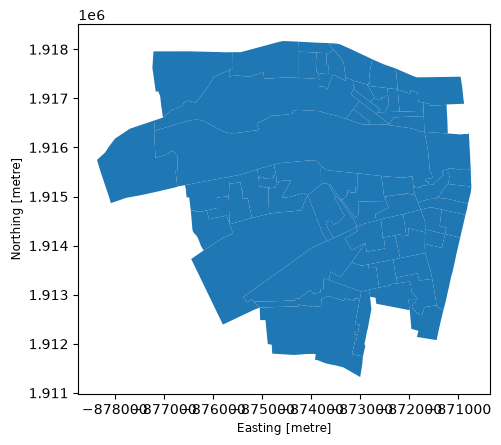

In [65]:
sonfile[sonfile['distrito_l']==6].plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

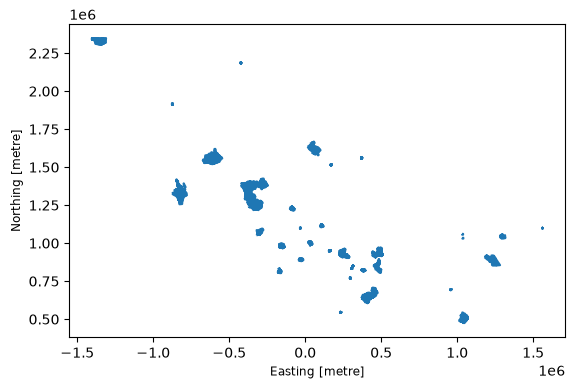

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

map6.plot(ax = ax)
map6.boundary.plot(ax = ax)